# FBref — datos reales, calidad y EDA

Six original statistical-category archives from GitHub releases, exported into target-season CSVs without cleaning source fields. Their exact archive/CSV hashes are in data/raw/source_manifest.json. Only FBref feeds the current recommender.

In [1]:
from pathlib import Path
import json
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
ROOT = Path.cwd()
while not (ROOT/'src/config.py').exists():
    if ROOT == ROOT.parent: raise RuntimeError('Run within the project')
    ROOT = ROOT.parent
import sys
sys.path.insert(0,str(ROOT))
from src.data.provenance import sha256
manifest=json.loads((ROOT/'data/processed/manifest.json').read_text(encoding='utf-8'))
def table(name):
    info=manifest['outputs'][name]
    path=ROOT/info['parquet_path']
    assert sha256(path)==info['parquet_sha256'], 'Prepared table checksum changed'
    return pd.read_parquet(path)


In [2]:
f=table('fbref_player_seasons'); g=table('fbref_scouting_gallery'); features=['gls_p90','ast_p90','sh_p90','sot_p90','crs_p90','int_p90','tklw_p90','fls_p90','fld_p90']
print('Player/league/season rows:',len(f),'Gallery rows:',len(g))
print('Duplicate entity/league/season keys:',int(f.duplicated(['entity_id','league','season']).sum()))
f.groupby(['league','season']).size().unstack(fill_value=0)

Player/league/season rows: 15948 Gallery rows: 7398
Duplicate entity/league/season keys: 0


season,2020-2021,2021-2022,2022-2023,2023-2024,2024-2025,2025-2026
league,,,,,,
Bundesliga,496,511,506,494,481,356
La Liga,570,603,583,598,589,435
Ligue 1,574,589,585,526,542,386
Premier League,524,537,554,570,562,402
Serie A,594,608,577,589,599,408


## Grain and identity

FBref category joins use source player ID + club + league + season, with exposure compatibility checks. Club stints are aggregated within player/league/season; unknown counts remain unknown. Cross-league histories remain separate. The gallery retains the highest-minutes league per player/season. Source snapshots do not prove historical publication timestamps.

In [3]:
quality=pd.DataFrame({'dtype':f.dtypes.astype(str),'missing':f.isna().sum(),'missing_pct':f.isna().mean()*100})
quality.sort_values('missing_pct',ascending=False)

,dtype,missing,missing_pct
valuation_date,object,15948,100.0
valuation_source,object,15948,100.0
xa,float64,15948,100.0
knowledge_date,datetime64[ns],15948,100.0
date_of_birth,object,15948,100.0
...,...,...,...
quality_outlier,bool,0,0.0
quality_inconsistent_counts,bool,0,0.0
clubs,object,0,0.0
club_count,int64,0,0.0


In [4]:
f[features].describe().T

,count,mean,std,min,25%,50%,75%,max
gls_p90,15947.0,0.117297,0.328480,0.0,0.000000,0.000000,0.142857,18.0
ast_p90,15947.0,0.087395,0.330989,0.0,0.000000,0.000000,0.107946,18.0
sh_p90,15947.0,1.249137,2.295443,0.0,0.252809,0.815710,1.812262,180.0
sot_p90,15947.0,0.400546,1.056245,0.0,0.000000,0.178453,0.561956,90.0
crs_p90,11314.0,1.718212,3.823157,0.0,0.058004,0.725482,2.476641,180.0
int_p90,11314.0,0.907045,2.371663,0.0,0.159327,0.720700,1.250000,90.0
tklw_p90,11314.0,0.962679,1.770769,0.0,0.320199,0.806480,1.242307,90.0
fls_p90,11314.0,1.447069,3.686026,0.0,0.646175,1.122988,1.637294,180.0
fld_p90,11314.0,1.214318,2.932512,0.0,0.392732,0.925450,1.538845,180.0


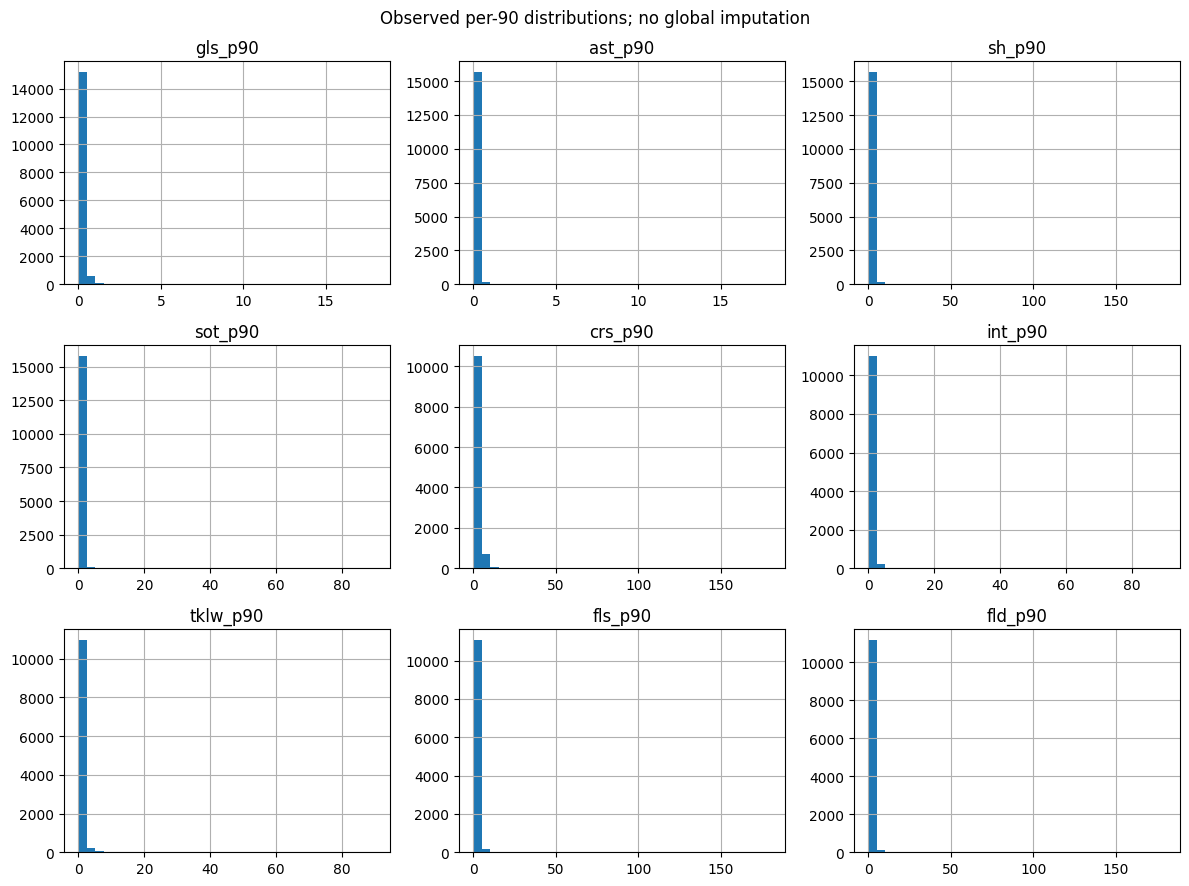

,iqr_flag_count
gls_p90,1515
ast_p90,1189
sh_p90,456
sot_p90,644
crs_p90,536
int_p90,220
tklw_p90,345
fls_p90,546
fld_p90,393


In [5]:
f[features].hist(bins=35,figsize=(12,9));plt.suptitle('Observed per-90 distributions; no global imputation');plt.tight_layout();plt.show()
q1=f[features].quantile(.25);q3=f[features].quantile(.75);iqr=q3-q1
pd.DataFrame({'iqr_flag_count':((f[features]<q1-1.5*iqr)|(f[features]>q3+1.5*iqr)).sum()})

## Missing values and outliers

Recent seasons retain standard statistics but lack aligned complete core categories. Gallery eligibility therefore removes incomplete profiles rather than filling them with invented observations. High per-90 rates may reflect low exposure or genuine rare events: IQR flags are diagnostic, not automatic deletions. Current modelling imputes/scales on training seasons only.

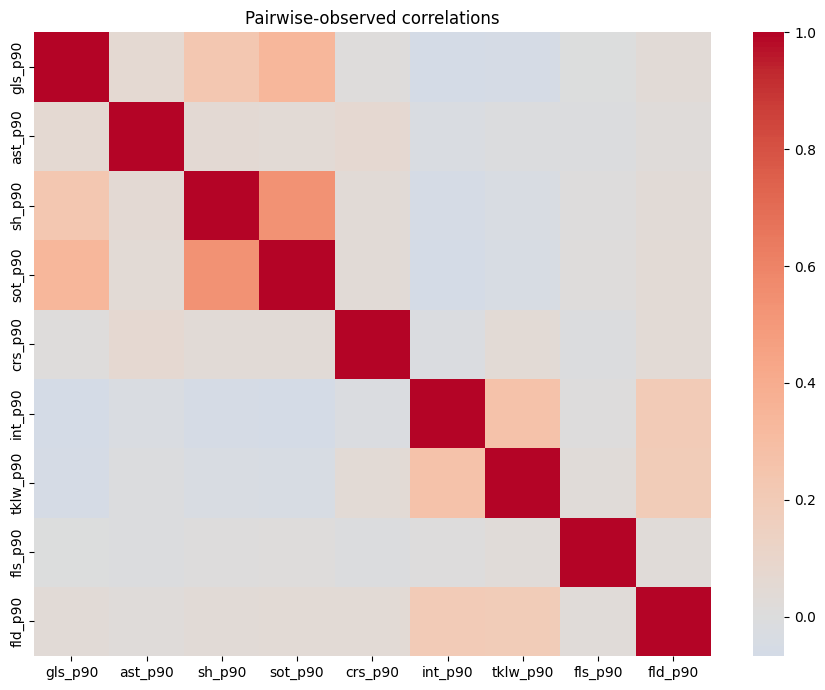

gls_p90   ast_p90    sh_p90   sot_p90  \
league     season    pos_main                                           
Bundesliga 2020-2021 DF        0.000000  0.000000  0.466858  0.121911   
                     FW        0.191288  0.095471  1.975196  0.790422   
                     GK        0.000000  0.000000  0.000000  0.000000   
                     MF        0.053035  0.064632  1.124331  0.329268   
           2021-2022 DF        0.000000  0.000000  0.487445  0.111524   
...                                 ...       ...       ...       ...   
Serie A    2024-2025 MF        0.029974  0.040315  1.131680  0.285476   
           2025-2026 DF        0.000000  0.000000  0.387931  0.000000   
                     FW        0.000000  0.000000  1.965066  0.389610   
                     GK        0.000000  0.000000  0.000000  0.000000   
                     MF        0.000000  0.000000  1.111111  0.000000   

                                crs_p90   int_p90  tklw_p90   fls_p90  \
league     season    pos_main                                           
Bundesliga 2020-2021 DF        1.038157  1.514681  0.961556  1.036411   
                     FW        0.915116  0.361119  0.429217  1.423495   
                     GK        0.000000  0.000000  0.000000  0.000000   
                     MF        0.924324  1.058824  1.005854  1.372434   
           2021-2022 DF        0.796460  1.411090  1.082474  0.953390   
...                                 ...       ...       ...       ...   
Serie A    2024-2025 MF        0.000000  0.000000  0.000000  0.542169   
           2025-2026 DF             NaN       NaN       NaN       NaN   
                     FW             NaN       NaN       NaN       NaN   
                     GK             NaN       NaN       NaN       NaN   
                     MF             NaN       NaN       NaN       NaN   

                                fld_p90  minutes  
league     season    pos_main                     
Bundesliga 2020-2021 DF        0.774316   1309.0  
                     FW        1.198655    829.0  
                     GK        0.054054   1665.0  
                     MF        1.304348   1198.0  
           2021-2022 DF        0.709169   1396.0  
...                                 ...      ...  
Serie A    2024-2025 MF        1.063253    989.5  
           2025-2026 DF             NaN    180.0  
                     FW             NaN    112.0  
                     GK             NaN    270.0  
                     MF             NaN    116.0  

[120 rows x 10 columns]

In [6]:
plt.figure(figsize=(9,7));sns.heatmap(f[features].corr(),cmap='coolwarm',center=0);plt.title('Pairwise-observed correlations');plt.tight_layout();plt.show()
f.groupby(['league','season','pos_main'])[features+['minutes']].median()

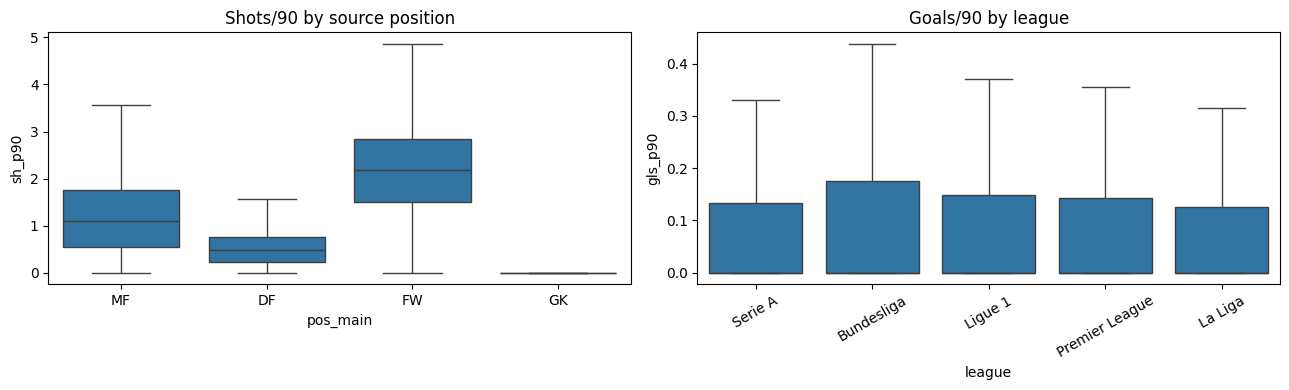

In [7]:
fig,axes=plt.subplots(1,2,figsize=(13,4))
sns.boxplot(data=f,x='pos_main',y='sh_p90',showfliers=False,ax=axes[0]);axes[0].set_title('Shots/90 by source position')
sns.boxplot(data=f,x='league',y='gls_p90',showfliers=False,ax=axes[1]);axes[1].tick_params(axis='x',rotation=30);axes[1].set_title('Goals/90 by league')
plt.tight_layout();plt.show()

## Interpretation and model boundary

Position and exposure affect distributions; league comparisons are descriptive, not causal. Correlated attacking rates motivate excluding goals+assists as a redundant feature. Complete six-style galleries end in 2023/24; four sparse 2024/25 gallery rows are not offered as a complete season. Full retrieval baselines, PCA/K-means loadings, stability and limitations are in 04_feature_comparison_and_model_validation.ipynb. These EDA plots do not validate transfer success.